# 3. Largest gap between sorted values

**Idea:** sort the distinct focal lengths. The gap between neighbours is small inside a group and large between groups. A gap is a **group boundary** when it is an outlier among all gaps, judged by the Tukey fence (Q3 + 1.5 × IQR) on the gaps.

**Suggested `eps`:** the largest gap that is *not* a boundary. Any two neighbours closer than this stay in one group.

**Reading the plot:** bars above the dashed fence are group boundaries.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().parent  # notebooks are run from the notebooks/ folder
if not (ROOT / "focal_data.py").is_file():
    raise FileNotFoundError(f"focal_data.py not found in {ROOT}; run from notebooks/")
sys.path.insert(0, str(ROOT))

from focal_data import load_focal_mm

DIRECTORY, DEPTH = r"D:\DCIM", 1
focal = load_focal_mm(DIRECTORY, DEPTH)
print(f"{len(focal)} images, focal length {focal.min():.0f}-{focal.max():.0f} mm, {len(np.unique(focal))} distinct values")


885 images, focal length 18-135 mm, 87 distinct values


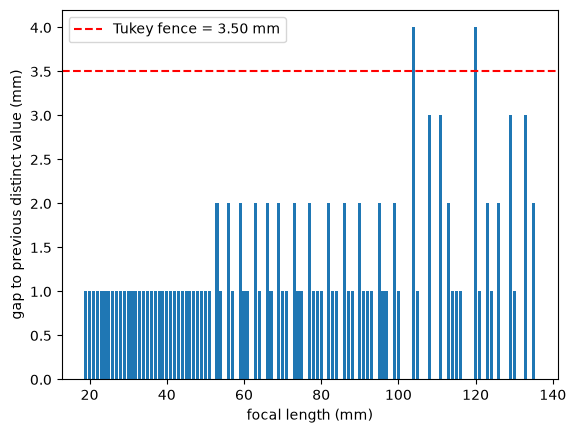

Group boundaries (mm, gap above them): [104.0, 120.0]
Suggested eps = largest non-boundary gap = 3.00 mm


In [2]:
values = np.unique(focal)
gaps = np.diff(values)

q1, q3 = np.percentile(gaps, [25, 75])
fence = q3 + 1.5 * (q3 - q1)  # Tukey outlier fence on the gaps
is_boundary = gaps > fence
eps = gaps[~is_boundary].max()

plt.bar(values[1:], gaps, width=0.8)
plt.axhline(fence, ls="--", color="red", label=f"Tukey fence = {fence:.2f} mm")
plt.xlabel("focal length (mm)")
plt.ylabel("gap to previous distinct value (mm)")
plt.legend()
plt.show()
print(f"Group boundaries (mm, gap above them): {np.round(values[1:][is_boundary], 1).tolist()}")
print(f"Suggested eps = largest non-boundary gap = {eps:.2f} mm")

## What to take away
If the boundaries land on sensible focal lengths (for example, the gap between prime lenses), the suggested `eps` separates them. If nothing exceeds the fence, the gaps are evenly spread and this method cannot find groups.